In [5]:
from pathlib import Path
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display, Latex, Markdown

from scipy.integrate import solve_ivp
from tqdm import tqdm

from scipy.stats import wilcoxon

SEED = 111
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')

Dispositivo: cpu


In [6]:
# 1. Parâmetros de Simulação e Tempo
m = 10000            # Número de motores virtuais (tamanho do banco de dados)
t_end = 2.0         # Tempo final de simulação (segundos)
deltaT = 0.01       # Período de amostragem (segundos)
t_eval = np.arange(0, t_end + deltaT, deltaT).reshape(1, -1) # Vetor de tempo 2D
n_amostras = t_eval.shape[1]

# A Inércia virtual é mantida constante em 1.0 para o treinamento
J_virtual = 1.0

# 2. Limites das Distribuições Uniformes para os Parâmetros (fiquem à vontade para ajustar)
# Valores hipotéticos plausíveis para um servo:
B_min, B_max = 0.5, 5.0
K_min, K_max = 20.0, 150.0
Tatrito_min, Tatrito_max = 0.5, 10.0
delta_min, delta_max = 0.01, 0.1 # Tolerância em radianos

# 3. Geração dos Vetores de Parâmetros Aleatórios (Labels Desejados)
# Usamos sementes (seed) para garantir a reprodutibilidade dos dados
np.random.seed(42)

B_arr = np.random.uniform(B_min, B_max, m).reshape(-1, 1)
K_arr = np.random.uniform(K_min, K_max, m).reshape(-1, 1)
Tatrito_arr = np.random.uniform(Tatrito_min, Tatrito_max, m).reshape(-1, 1)
delta_arr = np.random.uniform(delta_min, delta_max, m).reshape(-1, 1)

# Matriz de Labels (Y): m linhas x 4 colunas [B, K, T_atrito, delta]
Y_labels = np.hstack((B_arr, K_arr, Tatrito_arr, delta_arr))

print(f"Banco de dados inicializado para {m} motores.")
print(f"Formato esperado da Matriz de Features (X): ({m}, {n_amostras})")
print(f"Formato da Matriz de Labels (Y): {Y_labels.shape}")

Banco de dados inicializado para 10000 motores.
Formato esperado da Matriz de Features (X): (10000, 201)
Formato da Matriz de Labels (Y): (10000, 4)


In [7]:
# Inicialização da Matriz de Features (X) com zeros
X_features = np.zeros((m, n_amostras))

# Definição da Equação Diferencial Não-Linear
def servo_dynamics(t, state, B, K, T_atrito, delta, J):
    c, c_dot = state
    
    # Sinal de referência r(t): Degrau unitário
    r = 1.0 if t >= 0 else 0.0
    
    # Cálculo do Erro e Zona Morta (Deadband)
    e = r - c
    if abs(e) <= delta:
        db_e = 0.0
    else:
        db_e = e - delta * np.sign(e)
        
    # Atrito de Coulomb (Estático)
    # TRUQUE NUMÉRICO: Usamos tanh(100 * c_dot) em vez de np.sign(c_dot).
    # Isso suaviza a transição no zero e impede que o solver RK45 entre 
    # em loop infinito (chattering) tentando resolver descontinuidades bruscas.
    T_coulomb = T_atrito * np.tanh(100 * c_dot)
    
    # Equação Diferencial (J_virtual = 1, T_aero = 0 na bancada)
    # c_ddot = (K * DB) - (B * c_dot) - T_coulomb
    c_ddot = (K/J * db_e) - (B/J * c_dot) - T_coulomb/J
    
    return [c_dot, c_ddot]

In [8]:
# Loop de Simulação
print("Iniciando a integração numérica dos motores virtuais...")

# Condições Iniciais: Posição 0, Velocidade 0
state_0 = np.array([[0.0], [0.0]])
t_eval_solver = t_eval[0, :]

for i in tqdm(range(m), desc="Simulando Motores"):
    # Resgatando os parâmetros gerados no Bloco 1 para o motor 'i'
    B_i = B_arr[i, 0]
    K_i = K_arr[i, 0]
    Tatrito_i = Tatrito_arr[i, 0]
    delta_i = delta_arr[i, 0]
    
    # Resolvendo a EDO com o método Runge-Kutta 45
    sol = solve_ivp(
        fun=servo_dynamics, 
        t_span=(0, t_end), 
        y0=state_0[:, 0], 
        t_eval=t_eval_solver, 
        args=(B_i, K_i, Tatrito_i, delta_i, J_virtual),
        method='RK45'
    )
    
    # Armazenando a curva de posição (série temporal) na Matriz de Features
    X_features[i, :] = sol.y[0] + np.random.normal(0, 0.01, n_amostras)

print("Geração do banco de dados concluída!")
print(f"Matriz de Features final (X_features): {X_features.shape}")

Iniciando a integração numérica dos motores virtuais...


Simulando Motores: 100%|██████████| 10000/10000 [11:36<00:00, 14.35it/s]

Geração do banco de dados concluída!
Matriz de Features final (X_features): (10000, 201)


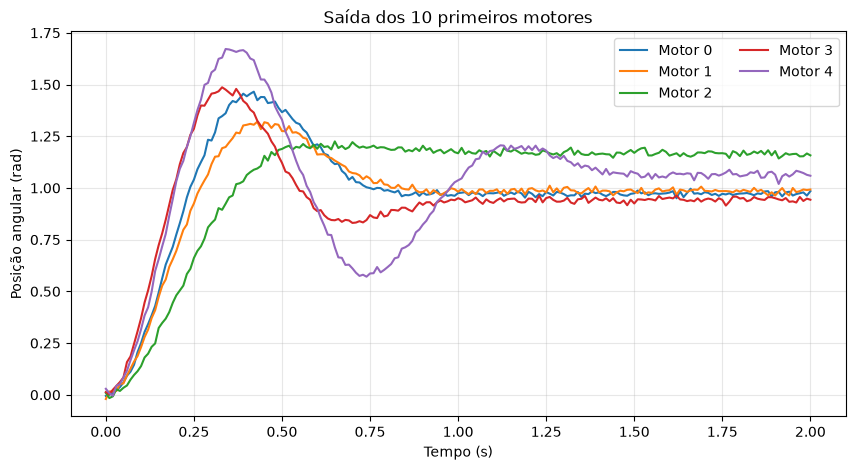

Shapes dos vetores e matrizes gerados:
t_eval: (1, 201)
r_input: (1, 201)
B_arr: (10000, 1)
K_arr: (10000, 1)
Tatrito_arr: (10000, 1)
delta_arr: (10000, 1)
Y_labels: (10000, 4)
state_0: (2, 1)
X_features: (10000, 201)
sol.t: (201,)
sol.y: (2, 201)


In [9]:
# Visualização dos 10 primeiros motores e diagnóstico dos shapes
r_input = np.ones_like(t_eval)

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(5):
    ax.plot(t_eval[0, :], X_features[i, :], label=f"Motor {i}", linewidth=1.5)

ax.set_title("Saída dos 10 primeiros motores")
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Posição angular (rad)")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
plt.show()

print("Shapes dos vetores e matrizes gerados:")
shapes = {
    "t_eval": t_eval.shape,
    "r_input": r_input.shape,
    "B_arr": B_arr.shape,
    "K_arr": K_arr.shape,
    "Tatrito_arr": Tatrito_arr.shape,
    "delta_arr": delta_arr.shape,
    "Y_labels": Y_labels.shape,
    "state_0": state_0.shape,
    "X_features": X_features.shape,
    "sol.t": sol.t.shape,
    "sol.y": sol.y.shape,
}
for name, shape in shapes.items():
    print(f"{name}: {shape}")

In [10]:
# Exportação do banco de dados para treinamento da MLP
feature_names = [f"feature_{i:03d}" for i in range(n_amostras)]
label_names = ["B", "K", "Tatrito", "delta"]
column_names = feature_names + label_names

dataset_mlp = np.hstack((X_features, Y_labels))

# Arquivo completo: features de entrada seguidas pelas labels de saída
np.savetxt(
    "database_mlp.csv",
    dataset_mlp,
    delimiter=",",
    header=",".join(column_names),
    comments="",
)

# Arquivos separados, caso a MLP seja treinada com X e Y em etapas diferentes
np.savetxt(
    "X_features.csv",
    X_features,
    delimiter=",",
    header=",".join(feature_names),
    comments="",
)
np.savetxt(
    "Y_labels.csv",
    Y_labels,
    delimiter=",",
    header=",".join(label_names),
    comments="",
)

print("Arquivos CSV exportados com sucesso:")
print("- database_mlp.csv:", dataset_mlp.shape)
print("- X_features.csv:", X_features.shape)
print("- Y_labels.csv:", Y_labels.shape)

Arquivos CSV exportados com sucesso:
- database_mlp.csv: (10000, 205)
- X_features.csv: (10000, 201)
- Y_labels.csv: (10000, 4)


# Previsao de parametros dos motores com MLP e Adam

Este notebook usa `X_features.csv` como entrada e `Y_labels.csv` como saida. A rede neural estima simultaneamente `B`, `K`, `Tatrito` e `delta`.

O conjunto de dados e separado em treino e teste antes da normalizacao. Os parametros da normalizacao sao calculados somente no treino para evitar vazamento de informacao.

## Carregamento e verificacao dos dados

In [11]:
# Usa os dados salvos em CSV pelas celulas da database.
target_names = ['B', 'K', 'Tatrito', 'delta']
X = pd.read_csv('X_features.csv').to_numpy(dtype=np.float32)
Y = pd.read_csv('Y_labels.csv').to_numpy(dtype=np.float32)

if X.shape[0] != Y.shape[0]:
    raise ValueError('X_features e Y_labels precisam ter o mesmo numero de amostras.')
if X.shape[1] != n_amostras:
    raise ValueError(f'Cada curva deve ter {n_amostras} amostras; encontrado: {X.shape[1]}')
if Y.shape[1] != len(target_names):
    raise ValueError(f'Y_labels precisa ter {len(target_names)} parametros; encontrado: {Y.shape[1]}')
if not np.isfinite(X).all() or not np.isfinite(Y).all():
    raise ValueError('Os dados contem valores NaN ou infinitos.')

print(f'Entradas: {X.shape[0]} motores x {X.shape[1]} amostras temporais')
print(f'Saidas: {Y.shape[1]} parametros ({target_names})')

Entradas: 10000 motores x 201 amostras temporais
Saidas: 4 parametros (['B', 'K', 'Tatrito', 'delta'])


## Separacao treino/teste e normalizacao

In [12]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X))
n_train = int(0.7 * len(X))
n_test = int(0.2 * len(X))
n_val = int(0.1 * len(X))
train_idx = indices[:n_train]
test_idx = indices[n_train:n_train + n_test]
val_idx = indices[n_train + n_test:n_train + n_test + n_val]

X_train, X_test, X_val = X[train_idx], X[test_idx], X[val_idx]
Y_train, Y_test, Y_val = Y[train_idx], Y[test_idx], Y[val_idx]

# Media e desvio-padrao sao obtidos apenas no conjunto de treino.
X_mean = X_train.mean(axis=0, keepdims=True)
X_std = X_train.std(axis=0, keepdims=True)
Y_mean = Y_train.mean(axis=0, keepdims=True)
Y_std = Y_train.std(axis=0, keepdims=True)
X_std[X_std < 1e-8] = 1.0
Y_std[Y_std < 1e-8] = 1.0

X_train_norm = (X_train - X_mean) / X_std
X_test_norm = (X_test - X_mean) / X_std
X_val_norm = (X_val - X_mean) / X_std
Y_train_norm = (Y_train - Y_mean) / Y_std
Y_test_norm = (Y_test - Y_mean) / Y_std
Y_val_norm = (Y_val - Y_mean) / Y_std

train_dataset = TensorDataset(torch.from_numpy(X_train_norm), torch.from_numpy(Y_train_norm))
test_dataset = TensorDataset(torch.from_numpy(X_test_norm), torch.from_numpy(Y_test_norm))
val_dataset = TensorDataset(torch.from_numpy(X_val_norm), torch.from_numpy(Y_val_norm))

# Tensores completos de validacao, usados diretamente dentro do loop de treinamento
X_val_tensor = torch.from_numpy(X_val_norm).to(device)
Y_val_tensor = torch.from_numpy(Y_val_norm).to(device)

print(f'Treino: {len(train_dataset)} amostras | Teste: {len(test_dataset)} amostras | Validacao: {len(val_dataset)} amostras')

Treino: 7000 amostras | Teste: 2000 amostras | Validacao: 1000 amostras


## Arquitetura da MLP

In [13]:
# Hiperparametros principais da MLP.
mini_batch_size = 64
number_of_epochs = 250
learning_rate = 1e-3
weight_decay = 1e-5
dropout_rate = 0.10

train_loader = DataLoader(
    train_dataset,
    batch_size=mini_batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
test_loader = DataLoader(
    test_dataset,
    batch_size=mini_batch_size,
    shuffle=False
)

In [14]:
class MLPRegressor(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, inputs):
        return self.network(inputs)

model_mlp = MLPRegressor(X_train.shape[1], len(target_names)).to(device)
linear = False

In [15]:
class MLPRegressor_simplified(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(64, output_dim)
        )

    def forward(self, inputs):
        return self.network(inputs)

model_mlp_reduzida = MLPRegressor_simplified(X_train.shape[1], len(target_names)).to(device)
linear = False

In [16]:
class LinearRegressor(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.network = nn.Linear(input_dim, output_dim)

    def forward(self, inputs):
        return self.network(inputs)

model_linear = LinearRegressor(X_train.shape[1], len(target_names)).to(device)
linear = True

## Treinamento com o otimizador Adam

In [17]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Linear') != -1:
        torch.nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
        torch.nn.init.zeros_(m.bias)

loss_function = nn.MSELoss()

def treinar_modelo(model, nome_modelo):
    """Inicializa os pesos, treina o modelo e retorna o modelo treinado + historico de loss."""
    if not isinstance(model, LinearRegressor):
        model.apply(weights_init)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    print(f'--- Treinando modelo: {nome_modelo} ---')
    print(model)
    print(f'Mini-batch: {mini_batch_size} | Epocas: {number_of_epochs} | LR: {learning_rate} | Weight decay: {weight_decay}\n')

    epochs = number_of_epochs
    batch_losses, val_batch_losses = [], []
    epoch_losses, val_epoch_losses = [], []
    best_loss = float('inf')
    best_state = None

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        epoch_val_loss = 0.0
        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()
            predictions = model(inputs)
            loss = loss_function(predictions, targets)
            loss.backward()
            optimizer.step()

            model.eval()
            with torch.no_grad():
                val_predictions = model(X_val_tensor)
                val_loss = loss_function(val_predictions, Y_val_tensor)
            model.train()

            loss_value = loss.item()
            val_loss_value = val_loss.item()
            batch_losses.append(loss_value)
            val_batch_losses.append(val_loss_value)
            epoch_loss += loss_value * len(inputs)
            epoch_val_loss += val_loss_value * len(inputs)

        epoch_loss /= len(train_dataset)
        epoch_val_loss /= len(train_dataset)
        epoch_losses.append(epoch_loss)
        val_epoch_losses.append(epoch_val_loss)
        if epoch_loss < best_loss:
            best_loss = epoch_loss
            best_state = copy.deepcopy(model.state_dict())
        if epoch % 10 == 0 or epoch == 0:
            print(f"Epoca: {epoch}/{epochs} Loss: {epoch_loss:.6f} Val. Loss: {epoch_val_loss:.6f}")

    model.load_state_dict(best_state)
    print(f'Menor loss medio de treino ({nome_modelo}): {best_loss:.6f}\n')

    historico = {
        'batch_losses': batch_losses,
        'val_batch_losses': val_batch_losses,
        'epoch_losses': epoch_losses,
        'val_epoch_losses': val_epoch_losses,
        'best_loss': best_loss
    }
    return model, historico

In [18]:
model_mlp, hist_mlp = treinar_modelo(model_mlp, 'MLP')
model_mlp_reduzida, hist_mlp_reduzida = treinar_modelo(model_mlp_reduzida, 'MLP Reduzida')
model_linear, hist_linear = treinar_modelo(model_linear, 'Linear')

--- Treinando modelo: MLP ---
MLPRegressor(
  (network): Sequential(
    (0): Linear(in_features=201, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=4, bias=True)
  )
)
Mini-batch: 64 | Epocas: 250 | LR: 0.001 | Weight decay: 1e-05

Epoca: 0/250 Loss: 0.736889 Val. Loss: 0.626822
Epoca: 10/250 Loss: 0.265704 Val. Loss: 0.214985
Epoca: 20/250 Loss: 0.199671 Val. Loss: 0.165198
Epoca: 30/250 Loss: 0.168858 Val. Loss: 0.140847
Epoca: 40/250 Loss: 0.152921 Val. Loss: 0.130372
Epoca: 50/250 Loss: 0.142729 Val. Loss: 0.123496
Epoca: 60/250 Loss: 0.133559 Val. Loss: 0.119529
Epoca: 70/250 Loss: 0.125488 Val. Loss: 0.113116
Epoca: 80/250 Loss: 0.121462 Val. Loss: 0.111275
Epoca: 90/250 Loss: 0.117307 Val. Loss: 0.110370
Epoc

## Funcao loss em funcao do numero do batch

In [19]:
output_dir = Path('resultados')
output_dir.mkdir(exist_ok=True)

# Mesmo criterio de escala usado antes: piso dinamico (menor loss observada
# entre os 3 modelos) e teto fixo em 2, agora compartilhado pelas 3 figuras.
historicos = {'MLP': hist_mlp, 'MLP Reduzida': hist_mlp_reduzida, 'Linear': hist_linear}
y_min = min(min(h['batch_losses']) for h in historicos.values())
y_max = 2

def plotar_loss(historico, nome_modelo, nome_arquivo):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(historico['batch_losses'], label='Loss (treino)')
    ax.plot(historico['val_batch_losses'], label='Val. Loss', alpha=0.8)
    ax.set_title(nome_modelo)
    ax.set_xlabel('Numero do batch')
    ax.set_ylabel('MSE loss (dados normalizados)')
    ax.set_ylim(y_min, y_max)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    fig.savefig(output_dir / nome_arquivo, dpi=150)
    plt.show()

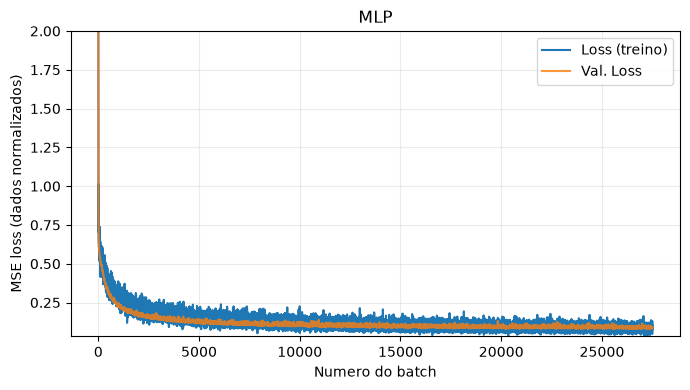

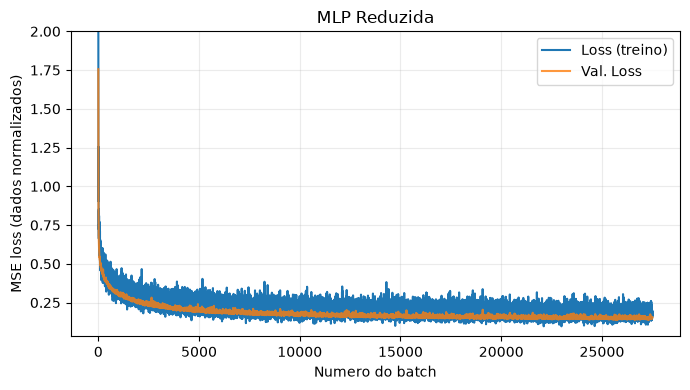

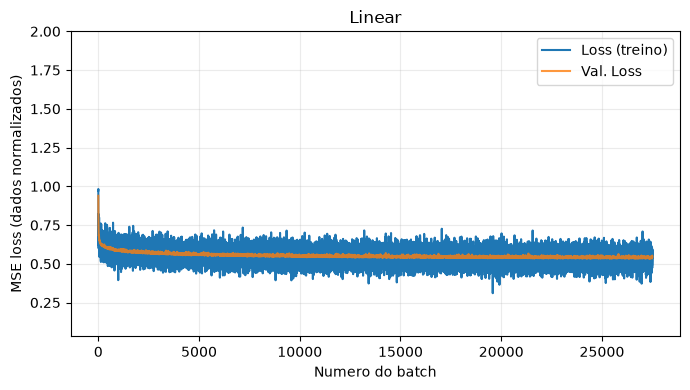

In [20]:
plotar_loss(hist_mlp, 'MLP', 'loss_mlp.png')
plotar_loss(hist_mlp_reduzida, 'MLP Reduzida', 'loss_mlp_reduzida.png')
plotar_loss(hist_linear, 'Linear', 'loss_linear.png')

## Avaliacao no conjunto de teste

In [21]:
latex_names = [
    r'B\ (\text{Atrito Viscoso})',
    r'K\ (\text{Ganho Estatico})',
    r'T_{atrito}\ (\text{Coulomb})',
    r'\delta\ (\text{Deadband})'
]

def avaliar_modelo(model, nome_modelo, nome_arquivo):
    model.eval()
    with torch.no_grad():
        Y_pred_norm = model(torch.from_numpy(X_test_norm).to(device)).cpu().numpy()
    Y_pred = Y_pred_norm * Y_std + Y_mean

    errors = Y_pred - Y_test
    absolute_errors = np.abs(errors)
    mae = absolute_errors.mean(axis=0)
    rmse = np.sqrt((errors ** 2).mean(axis=0))
    mape = (absolute_errors / np.maximum(np.abs(Y_test), 1e-8)).mean(axis=0) * 100
    ss_res = (errors ** 2).sum(axis=0)
    ss_tot = ((Y_test - Y_test.mean(axis=0)) ** 2).sum(axis=0)
    r2 = 1 - ss_res / np.maximum(ss_tot, 1e-12)
    rmse_mae_ratio = rmse / np.maximum(mae, 1e-8)

    metrics = pd.DataFrame(
        {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape, 'R2': r2, 'RMSE/MAE': rmse_mae_ratio},
        index=target_names
    )

    latex_rows = []
    for index, parameter in enumerate(latex_names):
        latex_rows.append(
            f'{parameter} & {mae[index]:.4f} & {rmse[index]:.4f} & '
            f'{mape[index]:.2f} & {r2[index]:.4f} & {rmse_mae_ratio[index]:.2f} \\\\'
        )

    caption = f"**Desempenho da Rede {nome_modelo} no Conjunto de Teste (N = {len(Y_test)})**"
    array_lines = [
        r'\begin{array}{lcccc}',
        r'\hline',
        r'\mathbf{Parametro} & \mathbf{MAE} & \mathbf{RMSE} & \mathbf{MAPE\ (\%)} & \mathbf{R}^{2} & \mathbf{\frac{RMSE}{MAE}} \\',
        r'\hline',
        *latex_rows,
        r'\hline',
        r'\end{array}'
    ]
    latex_array = '\n'.join(array_lines)

    display(Markdown(caption))
    display(Latex(latex_array))

    # Tabela salva em disco: .tex (pronto pra incluir em relatorio LaTeX) e .csv (dados brutos)
    with open(output_dir / f'{nome_arquivo}.tex', 'w') as f:
        f.write(latex_array)
    metrics.to_csv(output_dir / f'{nome_arquivo}.csv')

    return Y_pred

Y_pred_mlp = avaliar_modelo(model_mlp, 'MLP', 'tabela_mlp')
Y_pred_mlp_reduzida = avaliar_modelo(model_mlp_reduzida, 'MLP Reduzida', 'tabela_mlp_reduzida')
Y_pred_linear = avaliar_modelo(model_linear, 'Linear', 'tabela_linear')

**Desempenho da Rede MLP no Conjunto de Teste (N = 2000)**

<IPython.core.display.Latex object>

**Desempenho da Rede MLP Reduzida no Conjunto de Teste (N = 2000)**

<IPython.core.display.Latex object>

**Desempenho da Rede Linear no Conjunto de Teste (N = 2000)**

<IPython.core.display.Latex object>

MSE medio das curvas no conjunto de teste: 0.00114217
MSE do primeiro motor virtual de teste: 0.00013846


**MSE das curvas no Conjunto de Teste (N = 2000)**

<IPython.core.display.Latex object>

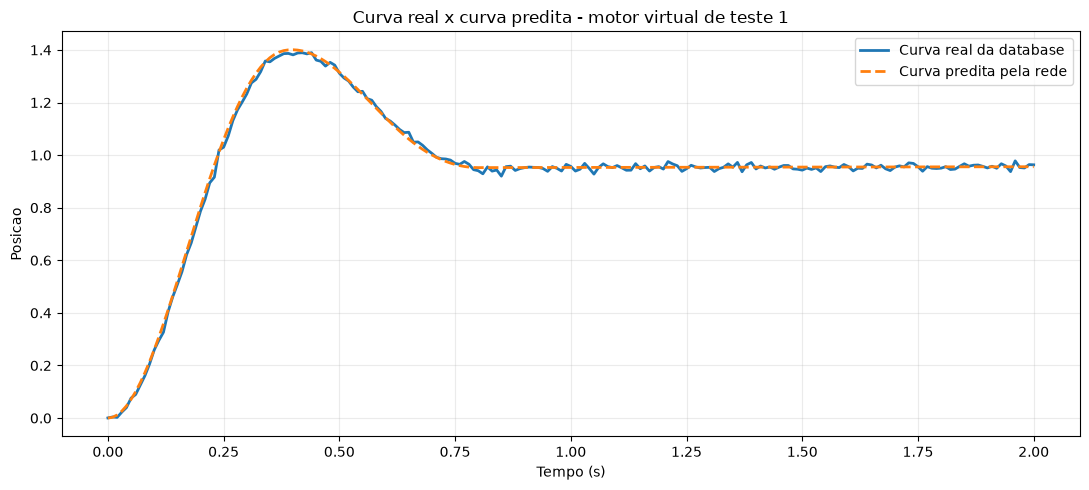

In [25]:
# Avaliacao temporal dos parametros preditos no conjunto de teste.
# Y_pred_mlp ja esta na escala original, calculado por avaliar_modelo.
Y_pred = Y_pred_mlp.astype(np.float64)

real_test_curves = X_test.astype(np.float64)
predicted_test_curves = np.zeros_like(real_test_curves)

for index, parameters in enumerate(Y_pred.astype(np.float64)):
    B_pred, K_pred, Tatrito_pred, delta_pred = parameters
    solution = solve_ivp(
        fun=servo_dynamics,
        t_span=(0.0, t_end),
        y0=state_0[:, 0],
        t_eval=t_eval_solver,
        args=(B_pred, K_pred, Tatrito_pred, delta_pred, J_virtual),
        method='RK45'
    )
    if not solution.success or solution.y.shape[1] != n_amostras:
        raise RuntimeError(f'Falha na simulacao do motor de teste {index + 1}: {solution.message}')
    predicted_test_curves[index] = solution.y[0]

curve_errors = predicted_test_curves - real_test_curves
mse_per_motor = np.mean(curve_errors ** 2, axis=1)
mse_test = np.mean(curve_errors ** 2)

print(f'MSE medio das curvas no conjunto de teste: {mse_test:.6g}')
print(f'MSE do primeiro motor virtual de teste: {mse_per_motor[0]:.6g}')

mse_caption = f"**MSE das curvas no Conjunto de Teste (N = {len(Y_test)})**"
mse_array = '\n'.join([
    r'\begin{array}{lc}',
    r'\hline',
    r'\mathbf{Metrica} & \mathbf{MSE} \\',
    r'\hline',
    fr'\text{{MSE medio das curvas}} & {mse_test:.6g} \\',
    r'\hline',
    r'\end{array}'
])
display(Markdown(mse_caption))
display(Latex(mse_array))

motor_index = 0
plt.figure(figsize=(11, 5))
plt.plot(t_eval_solver, real_test_curves[motor_index], label='Curva real da database', linewidth=2)
plt.plot(t_eval_solver, predicted_test_curves[motor_index], label='Curva predita pela rede', linewidth=2, linestyle='--')
plt.xlabel('Tempo (s)')
plt.ylabel('Posicao')
plt.title(f'Curva real x curva predita - motor virtual de teste {motor_index + 1}')
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
erros_mlp = np.abs(Y_test - Y_pred_mlp)
erros_linear = np.abs(Y_test - Y_pred_linear)

nomes_parametros = ['B (Atrito Viscoso)', 'K (Ganho Estatico)', 'Tatrito (Coulomb)', 'delta (Deadband)']

print("Resultados do Teste de Wilcoxon (Nivel de Significancia alpha = 0.001)\n")

for i, param in enumerate(nomes_parametros):
    erro_m = erros_mlp[:, i]
    erro_l = erros_linear[:, i]

    stat, p_value = wilcoxon(erro_m, erro_l, alternative='less')

    print(f"--- Parametro: {param} ---")
    print(f"Estatistica W: {stat:.4f} | p-value: {p_value:.4e}")

    if p_value < 0.001:
        print("Veredicto: Rejeitamos H0.")
        print("Interpretacao: Os erros provem de distribuicoes diferentes. A MLP possui um erro estatisticamente inferior.\n")
    else:
        print("Veredicto: Falhamos em rejeitar H0.")
        print("Interpretacao: Nao ha evidencias de que a MLP seja superior a Rede Linear neste parametro.\n")

Resultados do Teste de Wilcoxon (Nivel de Significancia alpha = 0.001)

--- Parametro: B (Atrito Viscoso) ---
Estatistica W: 172200.0000 | p-value: 0.0000e+00
Veredicto: Rejeitamos H0.
Interpretacao: Os erros provem de distribuicoes diferentes. A MLP possui um erro estatisticamente inferior.

--- Parametro: K (Ganho Estatico) ---
Estatistica W: 683348.0000 | p-value: 5.8983e-35
Veredicto: Rejeitamos H0.
Interpretacao: Os erros provem de distribuicoes diferentes. A MLP possui um erro estatisticamente inferior.

--- Parametro: Tatrito (Coulomb) ---
Estatistica W: 96329.0000 | p-value: 0.0000e+00
Veredicto: Rejeitamos H0.
Interpretacao: Os erros provem de distribuicoes diferentes. A MLP possui um erro estatisticamente inferior.

--- Parametro: delta (Deadband) ---
Estatistica W: 192397.0000 | p-value: 0.0000e+00
Veredicto: Rejeitamos H0.
Interpretacao: Os erros provem de distribuicoes diferentes. A MLP possui um erro estatisticamente inferior.



In [24]:
def inferir_parametros_servo(caminho_csv, modelo=None):
    """Infere os parametros do servo a partir de um CSV no formato X_features.csv.

    Cada linha deve conter uma curva com as colunas feature_000 a feature_200.
    Retorna um DataFrame com B, K, Tatrito e delta para cada curva.
    Requer o modelo treinado e X_mean, X_std, Y_mean, Y_std e target_names
    definidos apos executar o treinamento deste notebook.
    """
    if modelo is None:
        modelo = model_mlp

    n_features = X_mean.shape[1]
    feature_columns = [f'feature_{i:03d}' for i in range(n_features)]
    dados = pd.read_csv(caminho_csv)
    colunas_ausentes = [coluna for coluna in feature_columns if coluna not in dados.columns]
    if colunas_ausentes:
        raise ValueError(
            f'O CSV deve conter as {n_features} colunas de features '
            f'(feature_000 a feature_{n_features - 1:03d}). '
            f'Colunas ausentes: {colunas_ausentes[:5]}'
        )
    if dados.empty:
        raise ValueError('O CSV nao contem curvas para inferencia.')

    try:
        curvas = dados.loc[:, feature_columns].to_numpy(dtype=np.float32)
    except (TypeError, ValueError) as erro:
        raise ValueError('As amostras das curvas devem ser numericas.') from erro
    if not np.isfinite(curvas).all():
        raise ValueError('As curvas contem valores NaN ou infinitos.')

    curvas_norm = (curvas - X_mean) / X_std
    modelo.eval()
    with torch.no_grad():
        parametros_norm = modelo(torch.from_numpy(curvas_norm).to(device)).cpu().numpy()
    parametros = parametros_norm * Y_std + Y_mean
    return pd.DataFrame(parametros, columns=target_names)

# Exemplo, apos o treinamento: parametros = inferir_parametros_servo('curva_bancada.csv')